# 第 5 课 · 定价反事实与结课项目

同一家商店准备把商品 A 的统一报价从 8 元调到 9 元。店主想知道购买率会下降多少，以及一份随机报价样本能把这个差值估得多精确。

**建议用时 60 分钟，另做课后项目。** 课堂实验回到单品购买模型，接上[第一课的估计](01-binary-logit.ipynb)和[第二课的抽样推断](02-sampling-uncertainty.ipynb)。做完后，你能写清一个定价反事实、计算购买率的百分点差，并说明这项预测依赖哪些条件。

## 1. 把报价方案写成可比较的反事实

比较两个方案。基准方案给目标人群里的每一位顾客报 8 元，提价方案给同一人群里的每一位顾客报 9 元。两个价格都在原随机报价的范围内。两个方案的购买选项、偏好参数和效用冲击分布相同。

顾客按购买与不购买的效用差作选择。效用差为 $\alpha+\beta(p-8)+\varepsilon$，其中 $\varepsilon$ 服从标准 Logistic 分布。在第一课的报价规则下，价格独立于效用冲击。于是给定报价 $p$ 的购买概率为

$$
q(p;\theta)=\Lambda\bigl[\alpha+\beta(p-8)\bigr],
\qquad
\Lambda(z)=\frac{1}{1+e^{-z}},\quad \theta=(\alpha,\beta).
$$

统一报价时，这个概率就是模型预测的购买率。提价方案相对基准方案的购买率差，以百分点为单位，为

$$
\Delta(\theta)=100\bigl[q(9;\theta)-q(8;\theta)\bigr].
$$

### 重建随机报价样本

沿用第一课的参数和随机种子。每人从 5 到 11 元的七个整数价中独立抽取一个报价，模拟购买决策。保留报价和购买结果供估计使用。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm

reference_price = 8.0
true_parameters = np.array([0.60, -0.55])
sample_size = 2_000
sample_rng = np.random.default_rng(120)


def purchase_probability(price, parameters):
    intercept, price_coefficient = parameters
    return expit(intercept + price_coefficient * (price - reference_price))


price_levels = np.arange(5, 12)
price = sample_rng.choice(price_levels, size=sample_size)
shock = sample_rng.logistic(size=sample_size)
systematic_utility = true_parameters[0] + true_parameters[1] * (price - reference_price)
purchased = (systematic_utility + shock >= 0).astype(int)

print(f"模拟样本人数 {sample_size:,}，观察到的报价 {np.unique(price).tolist()} 元")
print(f"随机报价样本的平均购买率 {purchased.mean():.2%}")

模拟样本人数 2,000，观察到的报价 [5, 6, 7, 8, 9, 10, 11] 元
随机报价样本的平均购买率 63.60%


## 2. 估计价格系数并计算两种购买率

求解第一课的极大似然问题。代码对负平均对数似然求最小值，利用解析梯度缩短重复拟合的时间。价格系数的标准误由第二课的**总**似然信息矩阵给出。归一化效用里的价格系数用效用单位计量，购买率差用百分点计量。

In [2]:
def fit_logit(price, purchased):
    purchase_prices = price[purchased == 1]
    nonpurchase_prices = price[purchased == 0]
    if purchase_prices.size == 0 or nonpurchase_prices.size == 0:
        raise RuntimeError("购买决策没有变动")
    if np.ptp(price) == 0:
        raise RuntimeError("报价没有变动")
    if (
        purchase_prices.min() >= nonpurchase_prices.max()
        or nonpurchase_prices.min() >= purchase_prices.max()
    ):
        raise RuntimeError("购买决策在价格上完全分离或准完全分离")

    design = np.column_stack((np.ones(price.size), price - reference_price))

    def loss_and_gradient(parameters):
        index = design @ parameters
        loss = np.logaddexp(0.0, (1 - 2 * purchased) * index).mean()
        gradient = design.T @ (expit(index) - purchased) / price.size
        return loss, gradient

    fit = minimize(
        loss_and_gradient,
        x0=np.zeros(2),
        jac=True,
        method="BFGS",
        options={"gtol": 1e-7},
    )
    if not fit.success or not np.all(np.isfinite(fit.x)):
        raise RuntimeError(f"极大似然估计失败：{fit.message}")
    return fit.x


estimated_parameters = fit_logit(price, purchased)
fitted_purchase_probability = purchase_probability(price, estimated_parameters)
design = np.column_stack((np.ones(price.size), price - reference_price))
weights = fitted_purchase_probability * (1 - fitted_purchase_probability)
information = design.T @ (weights[:, None] * design)
covariance = np.linalg.solve(information, np.eye(2))
standard_errors = np.sqrt(covariance.diagonal())
critical_value = norm.ppf(0.975)
wald_intervals = estimated_parameters[:, None] + (
    critical_value * standard_errors[:, None] * np.array([-1, 1])
)

for name, value, se, (lower, upper) in zip(
    ("截距 α", "价格系数 β"), estimated_parameters, standard_errors, wald_intervals
):
    print(
        f"{name}  估计值 {value:.4f}，标准误 {se:.4f}，"
        f"95% Wald 区间 [{lower:.4f}, {upper:.4f}]"
    )

截距 α  估计值 0.6756，标准误 0.0546，95% Wald 区间 [0.5686, 0.7826]
价格系数 β  估计值 -0.5823，标准误 0.0300，95% Wald 区间 [-0.6411, -0.5235]


### 比较模型预测

这里给所有人分别代入 8 元和 9 元。随机报价样本的平均购买率混合了七个报价下的购买决策，与任一统一报价方案的预测购买率口径不同。

In [3]:
policy_prices = np.array([8, 9])
if not np.isin(policy_prices, price).all():
    raise ValueError("两个方案的报价都应在样本的报价支持范围内")

baseline_rate, policy_rate = purchase_probability(policy_prices, estimated_parameters)
change_pp = 100 * (policy_rate - baseline_rate)

print(f"统一报 {policy_prices[0]} 元，预测购买率 {baseline_rate:.2%}")
print(f"统一报 {policy_prices[1]} 元，预测购买率 {policy_rate:.2%}")
print(f"提价方案相对基准方案的变化 {change_pp:+.2f} 个百分点")

统一报 8 元，预测购买率 66.28%
统一报 9 元，预测购买率 52.33%
提价方案相对基准方案的变化 -13.94 个百分点


## 3. 衡量购买率差值的抽样不确定性

如果换一批购买记录，重新拟合得到的模型会给出稍有不同的购买率差。**参数自助法**（parametric bootstrap）用当前拟合的 Logit 充当模拟中的数据生成机制，以近似这种抽样波动。本例保留这份样本的各人报价，每次只重新模拟购买决策。

1. 保留每人原来抽到的价格 $p_i$，独立地以拟合概率 $q(p_i;\hat\theta)$ 生成一次购买结果。
2. 用这份模拟记录再估计一次，得到 $\hat\theta^{*}$。
3. 把同一组 $\hat\theta^{*}$ 代入两个报价方案，先在这一次拟合内做差，再保存差值 $\Delta(\hat\theta^{*})$。
4. 重复 500 次，用这些差值的第 2.5 和第 97.5 百分位数构造近似的 95% 区间。

两个方案共用一次拟合，保留了两个预测随估计结果一起变化的关系。这里的区间在给定观测报价、模型正确设定的前提下反映抽样波动。有限样本下，区间的覆盖率可能偏离名义的 95%，端点也会随自助模拟的随机种子略有波动。 [Geyer 的 Logit 参数自助法示例](https://www.stat.umn.edu/geyer/8701/parm/)

In [4]:
bootstrap_repetitions = 500
bootstrap_rng = np.random.default_rng(2027)
bootstrap_changes = []
failure_messages = []

for _ in range(bootstrap_repetitions):
    bootstrap_purchased = bootstrap_rng.binomial(1, fitted_purchase_probability)
    try:
        bootstrap_parameters = fit_logit(price, bootstrap_purchased)
    except RuntimeError as error:
        failure_messages.append(str(error))
        continue

    bootstrap_baseline, bootstrap_policy = purchase_probability(
        policy_prices, bootstrap_parameters
    )
    bootstrap_changes.append(100 * (bootstrap_policy - bootstrap_baseline))

print(f"成功拟合 {len(bootstrap_changes)} 次，失败 {len(failure_messages)} 次")
if failure_messages:
    raise RuntimeError(f"先检查失败原因再汇总区间。首个失败原因：{failure_messages[0]}")

interval_lower, interval_upper = np.quantile(bootstrap_changes, [0.025, 0.975])
print(f"购买率差的 95% 自助法区间 [{interval_lower:.2f}, {interval_upper:.2f}] 个百分点")

成功拟合 500 次，失败 0 次
购买率差的 95% 自助法区间 [-15.34, -12.54] 个百分点


### 读图与读区间

横轴是每次拟合给出的购买率百分点差。竖实线是原样本估计，阴影是差值的百分位区间。区间衡量的是**总体购买率差**的估计精度。单个顾客在两种报价下是否会买，属于另一个问题。

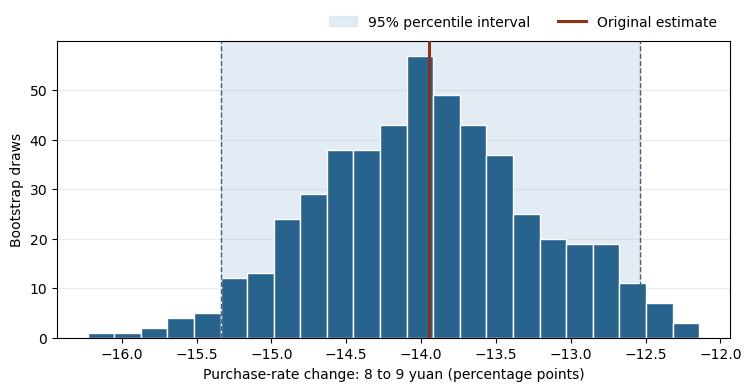

In [5]:
fig, ax = plt.subplots(figsize=(7.4, 3.8), layout="constrained")
ax.hist(bootstrap_changes, bins=23, color="#28638e", edgecolor="white", zorder=2)
ax.axvspan(
    interval_lower, interval_upper,
    color="#c8dbeb", alpha=0.5, label="95% percentile interval",
)
ax.axvline(change_pp, color="#8d3116", linewidth=2.2, zorder=3, label="Original estimate")
ax.axvline(interval_lower, color="#425f73", linestyle="--", linewidth=1, zorder=3)
ax.axvline(interval_upper, color="#425f73", linestyle="--", linewidth=1, zorder=3)
ax.set(
    xlabel=f"Purchase-rate change: {policy_prices[0]} to {policy_prices[1]} yuan (percentage points)",
    ylabel="Bootstrap draws",
)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2, frameon=False)
plt.show()

## 4. 改变一项条件，重算反事实

刚才假设目标人群的基准购买意愿与实验样本相同。做一个敏感性分析。设想目标人群对这件商品的系统性效用统一增加 0.40，价格系数与冲击分布按原设定，两种报价方案都面对这批顾客。我们把截距加上 0.40，再比较同一组报价。这是规定的情景参数，它的数值没有用样本估计。

因为 Logit 曲线的斜率随效用指数变化，即使价格系数保持不变，购买率差也可能改变。这个比较回答的是对一项假设的敏感程度。上节的区间回答的是固定模型和情景下的抽样精度。

In [6]:
intercept_shift = 0.40
shifted_parameters = estimated_parameters + np.array([intercept_shift, 0])
shifted_baseline, shifted_policy = purchase_probability(policy_prices, shifted_parameters)

print(f"原模型  {baseline_rate:.2%} → {policy_rate:.2%}，变化 {change_pp:+.2f} 个百分点")
shifted_change_pp = 100 * (shifted_policy - shifted_baseline)
print(
    f"提高基准购买意愿  {shifted_baseline:.2%} → {shifted_policy:.2%}，"
    f"变化 {shifted_change_pp:+.2f} 个百分点"
)

原模型  66.28% → 52.33%，变化 -13.94 个百分点
提高基准购买意愿  74.57% → 62.09%，变化 -12.48 个百分点


### 回到识别问题

在本例中，报价随机且不取决于顾客的效用冲击，因此同价顾客的购买决策能用来估计模型在该价位的购买概率。用模型比较统一报价还需要相信两个方案对应的是同一目标人群，且报价以外的条件按分析设定。若报价由商店依据研究者看不见的购买意愿给出，直接照这一课拟合和自助模拟，所得区间依赖这一内生报价关系，价格效应仍需额外的识别依据。分析实际数据时，要核对报价记录和随机化方案，或说明其他外生价格变动从何而来。 [第 4 课](04-price-endogeneity.ipynb)

## 课堂练习

1. 把两个报价改为 7 元和 8 元，从比较方案的单元格起重跑。计算购买率差和自助法区间，解释两次同幅度提价为何可能有不同的百分点影响。
2. 在原报价方案下，把自助模拟次数改为 200 和 1,000，分别重跑。比较两个区间端点。说明增加重复次数会影响哪一层模拟误差，以及想让估计更精确时还需要改变什么。
3. 把假定的截距变化改为 −0.40，重算两个方案下的购买率和差值。解释这个结果依赖什么条件，并用一句话区分情景敏感性与抽样不确定性。
4. 假设商店可给购买意愿更强的人报更高的价格。写出最可能被破坏的独立性条件，并列出一项你需要查看的报价制度证据。

## 结课项目

用同一家商店的**随机报价模拟数据**比较两个支持范围内的报价方案。基础项目沿用本课二元 Logit。可以改变模拟种子、样本量或报价组合，在 Notebook 开头写清所选方案和设定。估计只读报价与购买记录，模拟真值可用于回顾估计表现。

1. **确定比较。** 写出目标顾客、选择集合、效用方程、两种方案和比较指标。交代报价如何生成，为什么这类价格变动可以用于识别。
2. **估计并报告。** 报告系数、标准误和置信区间。核对所有方案报价是否出现在估计样本中。
3. **预测并检查一项条件。** 报告两种方案的购买率、百分点差及差值区间。写清保持固定的条件，再改变一项条件做敏感性分析。
4. **提交两份材料。** 提交一份能从干净内核按顺序运行的 Notebook，另交一页给商店的备忘录。列出所用的随机种子，核对备忘录数字与输出。

**选做扩展。** 按[第三课](03-multinomial-logit.ipynb)生成两件商品的随机报价样本，估计三选项 Logit。先固定 B 的价格，比较 A 提价前后 A、B 和不购买的预测份额。再设 B 同时调价，用百分点报告变化，检查每个方案的三项份额是否加总为 100%。如计算份额差的区间，固定观测到的报价组合，按原模型拟合的选择概率为每位顾客生成一个选项，再用新模拟记录拟合。每次用同一组新估计参数计算两个方案，再保存差值。还可以用重复估计所得价格系数的标准差和分位数报告系数的自助法标准误和区间。

### 一页备忘录提纲

| 段落 | 回答的问题 |
| --- | --- |
| 比较对象 | 给同一人群的两个报价是什么？哪些选择和条件保持固定？ |
| 数据与识别 | 报价怎样生成？估计依赖什么外生变动？ |
| 预测与精度 | 两种方案的预测购买率分别是多少？差多少个百分点？差值区间怎么读？ |
| 适用范围 | 改变一项条件以后，结果如何变化？若用实际报价数据，要核对什么？ |

购买率反映购买人数的比例。若报告销售收入，须交代价格、顾客人数和销量口径。讨论利润或消费者福利需要另外给出成本或福利测度的条件。评分按[课程设计](../COURSE.md)执行。模型与识别 30%，估计与推断 30%，反事实解释 25%，可复现性 15%。